# Лабораторна робота №5: Інженерія даних для задачі кластеризації

**Дисципліна:** Методи та технології інженерії даних  
**Виконав:** студент 3-го курсу групи ФеП-32 Чепара Станіслав  
**Датасет:** Automobile Data (205 спостережень, 26 характеристик)


## Мета роботи
Навчитися виконувати підготовку та перетворення даних для задачі кластеризації, формувати різні набори ознак, застосовувати масштабування та метод головних компонент (PCA), визначати оптимальну кількість кластерів і досліджувати вплив просторового представлення даних на результати кластеризації.


In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Налаштування стилю графіків
sns.set_theme(style='whitegrid', font_scale=1.0)
os.makedirs('plots', exist_ok=True)
print("Бібліотеки успішно імпортовано.")


Бібліотеки успішно імпортовано.


## Завдання 1. Підготовка даних за результатами EDA
1. Завантажити набір даних `Automobile_data.csv`.
2. Замінити пропуски, позначені `'?'`, на `np.nan`.
3. Привести числові стовпці до відповідних типів і заповнити пропуски медіаною.
4. Заповнити категоріальні пропуски модою.
5. Перевірити наявність дублікатів.
6. Вилучити службову ознаку `symboling` (страховий ризик-рейтинг, що був міткою в класифікації).


In [2]:
# 1. Завантаження даних
df = pd.read_csv('Automobile_data.csv')
print(f"Початковий розмір: {df.shape[0]} рядків, {df.shape[1]} стовпців")

# 2. Заміна '?' на NaN
df = df.replace('?', np.nan)

# Визначення числових та категоріальних ознак
numeric_cols = [
    'normalized-losses', 'wheel-base', 'length', 'width', 'height',
    'curb-weight', 'engine-size', 'bore', 'stroke', 'compression-ratio',
    'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price'
]

categorical_cols = [
    'make', 'fuel-type', 'aspiration', 'num-of-doors', 'body-style',
    'drive-wheels', 'engine-location', 'engine-type', 'num-of-cylinders',
    'fuel-system'
]

# 3. Приведення типів та заповнення медіаною
for col in numeric_cols:
    s = pd.to_numeric(df[col], errors='coerce')
    df[col] = s.fillna(s.median())

# 4. Заповнення модою
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# 5. Перевірка дублікатів
print(f"Дублікатів у вибірці: {df.duplicated().sum()}")

# 6. Вилучення службового поля symboling
X_raw = df.drop(columns=['symboling'])
print(f"Розмірність після вилучення symboling: {X_raw.shape}")
print(f"Всього пропусків після обробки: {X_raw.isnull().sum().sum()}")


Початковий розмір: 205 рядків, 26 стовпців
Дублікатів у вибірці: 0
Розмірність після вилучення symboling: (205, 25)
Всього пропусків після обробки: 0


## Завдання 2. Підготовка числових і категоріальних ознак
- **StandardScaler** для числових колонок (приведення до $\mu=0, \sigma=1$).
- **OneHotEncoder(drop='first')** для категоріальних колонок.
- **ColumnTransformer** для об'єднання перетворень.

> **Обґрунтування масштабування:** Алгоритм K-Means мінімізує суму квадратів евклідових відстаней $d(p, q) = \sqrt{\sum (p_i - q_i)^2}$. Якщо величини не стандартизувати, ознаки з великим абсолютним масштабом (наприклад, ціна від 5 000 до 45 000 чи споряджена маса від 1 500 до 4 000 кг) створять різницю у квадратах на рівні $10^8$, повністю придушивши вплив геометричних параметрів, витрати пального та типу двигуна.


## Завдання 3. Формування різних наборів ознак (A, B, C)
- **Набір A (усі ознаки):** 15 числових + 10 категоріальних (65 стовпців після OHE).
- **Набір B (відібрані ознаки):** усунення мультиколінеарності (`highway-mpg`, `length`, `width`), квазіконстант (`engine-location`), розріджених категорій (`make` — 22 марки). Залишено 6 числових і 2 ключові категоріальні ознаки (12 колонок після OHE).
- **Набір C (PCA):** застосування методу головних компонент до стандартизованих числових ознак для покриття $\ge 90\%$ дисперсії (7 компонент).


Розмірність Набору A: (205, 65)


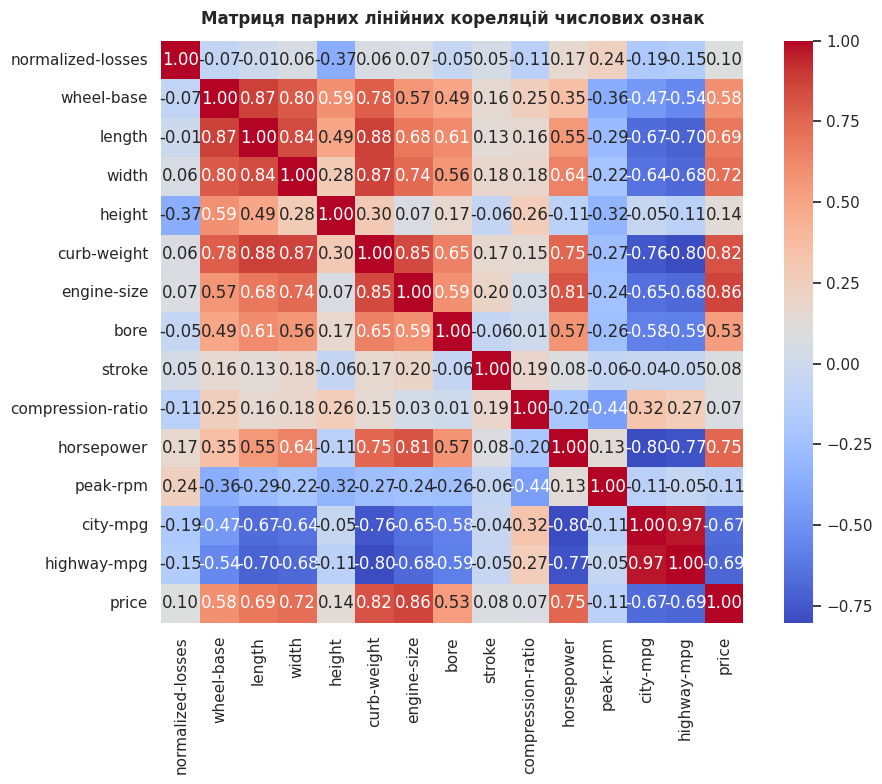

Розмірність Набору B: (205, 12) (6 числових + 6 бінарних після OHE)
PCA: 90% дисперсії покривають 7 компонент (92.53%)
PCA: 95% дисперсії покривають 9 компонент (96.53%)


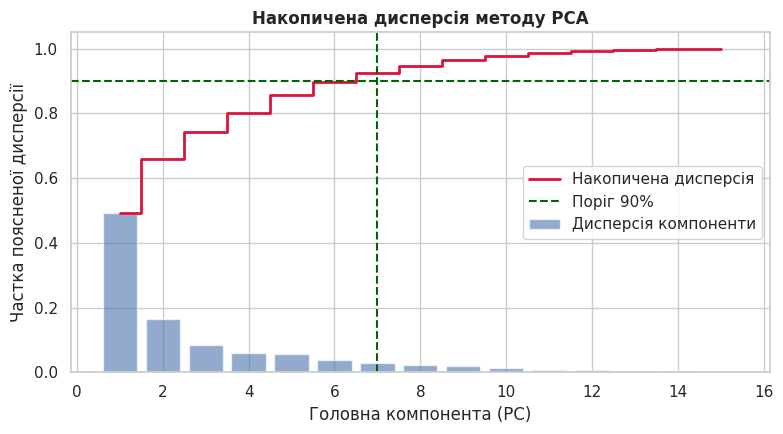

Розмірність Набору C: (205, 7)


In [3]:
# 1. Набір A — Усі ознаки
ct_all = ColumnTransformer([
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_cols)
])
X_A = ct_all.fit_transform(X_raw)
print(f"Розмірність Набору A: {X_A.shape}")

# 2. Матриця кореляцій числових ознак
corr = df[numeric_cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title('Матриця парних лінійних кореляцій числових ознак', fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

# 3. Набір B — Відібрані ознаки
selected_num = ['curb-weight', 'wheel-base', 'horsepower', 'city-mpg', 'price', 'compression-ratio']
selected_cat = ['body-style', 'drive-wheels']

ct_B = ColumnTransformer([
    ('num', StandardScaler(), selected_num),
    ('cat', OneHotEncoder(drop='first', sparse_output=False), selected_cat)
])
X_B = ct_B.fit_transform(X_raw)
print(f"Розмірність Набору B: {X_B.shape} (6 числових + 6 бінарних після OHE)")

# 4. Набір C — PCA на числових ознаках
scaler_num = StandardScaler()
X_num_scaled = scaler_num.fit_transform(df[numeric_cols])

pca_full = PCA().fit(X_num_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_comp_90 = int(np.argmax(cum_var >= 0.90) + 1)
n_comp_95 = int(np.argmax(cum_var >= 0.95) + 1)

print(f"PCA: 90% дисперсії покривають {n_comp_90} компонент ({cum_var[n_comp_90-1]*100:.2f}%)")
print(f"PCA: 95% дисперсії покривають {n_comp_95} компонент ({cum_var[n_comp_95-1]*100:.2f}%)")

plt.figure(figsize=(8, 4.5))
plt.bar(range(1, len(cum_var)+1), pca_full.explained_variance_ratio_, alpha=0.6, label='Дисперсія компоненти')
plt.step(range(1, len(cum_var)+1), cum_var, where='mid', color='crimson', lw=2, label='Накопичена дисперсія')
plt.axhline(0.90, color='darkgreen', linestyle='--', label='Поріг 90%')
plt.axvline(n_comp_90, color='darkgreen', linestyle='--')
plt.xlabel('Головна компонента (PC)')
plt.ylabel('Частка поясненої дисперсії')
plt.title('Накопичена дисперсія методу PCA', fontweight='bold')
plt.legend(loc='center right')
plt.tight_layout()
plt.show()

# Формуємо Набір C
pca_model = PCA(n_components=n_comp_90, random_state=42)
X_C = pca_model.fit_transform(X_num_scaled)
print(f"Розмірність Набору C: {X_C.shape}")


## Завдання 4. Визначення кількості кластерів (k ∈ [2, 10])
Досліджуємо зміну показника Inertia (WCSS) та Silhouette Score для визначення точки ліктя та максимуму силуету.


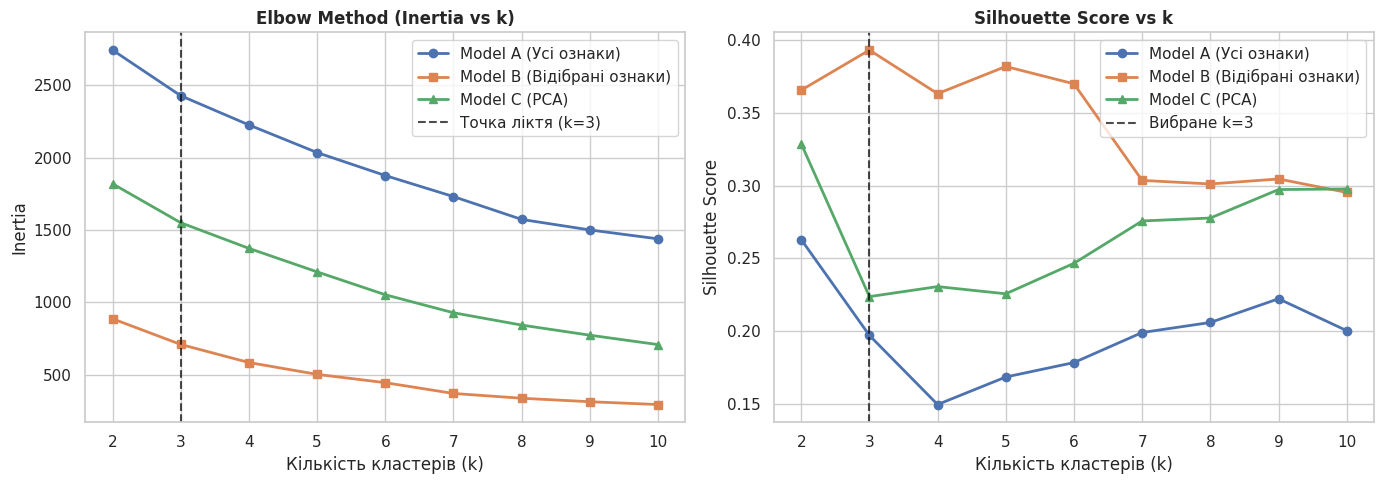

Оптимальне значення k = 3 підтверджується вигином інерції та високим силуетом для Набору B (0.3934).


In [4]:
k_range = list(range(2, 11))
inertias = {'A': [], 'B': [], 'C': []}
silhouettes = {'A': [], 'B': [], 'C': []}

for k in k_range:
    # Model A
    kmA = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_A)
    inertias['A'].append(kmA.inertia_)
    silhouettes['A'].append(silhouette_score(X_A, kmA.labels_))
    # Model B
    kmB = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_B)
    inertias['B'].append(kmB.inertia_)
    silhouettes['B'].append(silhouette_score(X_B, kmB.labels_))
    # Model C
    kmC = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_C)
    inertias['C'].append(kmC.inertia_)
    silhouettes['C'].append(silhouette_score(X_C, kmC.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(k_range, inertias['A'], marker='o', lw=2, label='Model A (Усі ознаки)')
ax1.plot(k_range, inertias['B'], marker='s', lw=2, label='Model B (Відібрані ознаки)')
ax1.plot(k_range, inertias['C'], marker='^', lw=2, label='Model C (PCA)')
ax1.axvline(3, color='black', linestyle='--', alpha=0.7, label='Точка ліктя (k=3)')
ax1.set_xlabel('Кількість кластерів (k)')
ax1.set_ylabel('Inertia')
ax1.set_title('Elbow Method (Inertia vs k)', fontweight='bold')
ax1.legend()

ax2.plot(k_range, silhouettes['A'], marker='o', lw=2, label='Model A (Усі ознаки)')
ax2.plot(k_range, silhouettes['B'], marker='s', lw=2, label='Model B (Відібрані ознаки)')
ax2.plot(k_range, silhouettes['C'], marker='^', lw=2, label='Model C (PCA)')
ax2.axvline(3, color='black', linestyle='--', alpha=0.7, label='Вибране k=3')
ax2.set_xlabel('Кількість кластерів (k)')
ax2.set_ylabel('Silhouette Score')
ax2.set_title('Silhouette Score vs k', fontweight='bold')
ax2.legend()

plt.tight_layout()
plt.show()

print("Оптимальне значення k = 3 підтверджується вигином інерції та високим силуетом для Набору B (0.3934).")


## Завдання 5 та 6. Побудова моделей кластеризації та оцінювання якості
Будуємо моделі K-Means при $k = 3$ та обчислюємо комплекс метрик якості:
- **Inertia**
- **Silhouette Score** (більше — краще)
- **Davies-Bouldin Index** (менше — краще)
- **Calinski-Harabasz Index** (більше — краще)


In [5]:
km_A = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_A)
km_B = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_B)
km_C = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_C)

df['cluster_A'] = km_A.labels_
df['cluster_B'] = km_B.labels_
df['cluster_C'] = km_C.labels_

results = [
    {
        'Модель': 'Model A (Усі ознаки)',
        'Ознаки': X_A.shape[1],
        'Inertia': round(km_A.inertia_, 2),
        'Silhouette': round(silhouette_score(X_A, km_A.labels_), 4),
        'Davies-Bouldin': round(davies_bouldin_score(X_A, km_A.labels_), 4),
        'Calinski-Harabasz': round(calinski_harabasz_score(X_A, km_A.labels_), 1)
    },
    {
        'Модель': 'Model B (Відібрані ознаки)',
        'Ознаки': X_B.shape[1],
        'Inertia': round(km_B.inertia_, 2),
        'Silhouette': round(silhouette_score(X_B, km_B.labels_), 4),
        'Davies-Bouldin': round(davies_bouldin_score(X_B, km_B.labels_), 4),
        'Calinski-Harabasz': round(calinski_harabasz_score(X_B, km_B.labels_), 1)
    },
    {
        'Модель': 'Model C (PCA 7 компонент)',
        'Ознаки': X_C.shape[1],
        'Inertia': round(km_C.inertia_, 2),
        'Silhouette': round(silhouette_score(X_C, km_C.labels_), 4),
        'Davies-Bouldin': round(davies_bouldin_score(X_C, km_C.labels_), 4),
        'Calinski-Harabasz': round(calinski_harabasz_score(X_C, km_C.labels_), 1)
    }
]

df_res = pd.DataFrame(results)
display(df_res)


,Модель,Ознаки,Inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,Model A (Усі ознаки),65,2429.12,0.1971,1.8109,60.0
1,Model B (Відібрані ознаки),12,708.13,0.3934,1.0182,106.4
2,Model C (PCA 7 компонент),7,1550.38,0.2238,1.4968,84.4


## Завдання 7. Візуалізація кластерів у 2D (PC1 × PC2)
Відображаємо об'єкти на площині перших двох головних компонент (PC1 і PC2, 65.8% дисперсії) разом з емпіричними центроїдами кластерів.


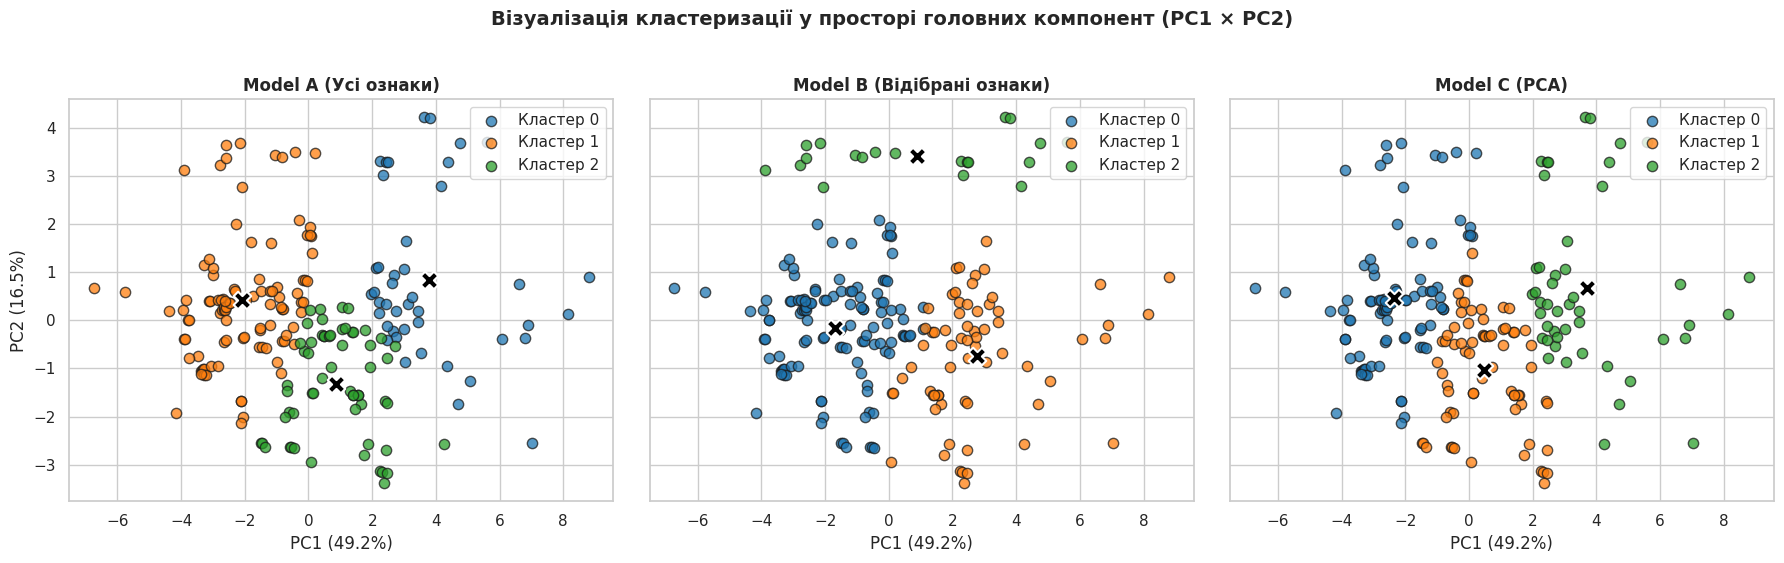

In [6]:
pca_2d = PCA(n_components=2, random_state=42)
X_2d = pca_2d.fit_transform(X_num_scaled)
df['PC1'] = X_2d[:, 0]
df['PC2'] = X_2d[:, 1]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharex=True, sharey=True)
models = [
    ('Model A (Усі ознаки)', 'cluster_A', axes[0]),
    ('Model B (Відібрані ознаки)', 'cluster_B', axes[1]),
    ('Model C (PCA)', 'cluster_C', axes[2])
]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for title, col, ax in models:
    for cl in sorted(df[col].unique()):
        sub = df[df[col] == cl]
        ax.scatter(sub['PC1'], sub['PC2'], color=colors[cl], label=f'Кластер {cl}', alpha=0.75, edgecolors='k', s=55)
        # Емпіричний центроїд
        ax.scatter(sub['PC1'].mean(), sub['PC2'].mean(), color='black', marker='X', s=160, edgecolors='white', linewidths=1.5)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)')
    if ax == axes[0]:
        ax.set_ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)')
    ax.legend(loc='upper right')

plt.suptitle('Візуалізація кластеризації у просторі головних компонент (PC1 × PC2)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## Завдання 8. Аналіз та профілювання отриманих кластерів (Model B)
Формуємо детальний профіль кожного кластера за ціною, потужністю, масою, витратою пального, типом кузова та двигуна.


=== Бюджетний економічний сегмент (Масові авто) (Кластер 0, n=119) ===
Ціна: середня $8614, медіана $8195
Потужність: 83.7 к.с.
Маса: 2221 кг, Колісна база: 95.7"
Витрата в місті: 28.0 mpg
Ступінь стиснення: 9.0
Паливо: {'gas': 119}
Привод: {'fwd': 96, 'rwd': 16, '4wd': 7}
Топ марки: {'toyota': 24, 'honda': 13, 'mazda': 13}

=== Преміальний та спортивний сегмент (Люкс-авто) (Кластер 1, n=66) ===
Ціна: середня $20514, медіана $17324
Потужність: 147.0 к.с.
Маса: 3055 кг, Колісна база: 102.6"
Витрата в місті: 18.6 mpg
Ступінь стиснення: 8.6
Паливо: {'gas': 66}
Привод: {'rwd': 49, 'fwd': 15, '4wd': 2}
Топ марки: {'volvo': 10, 'bmw': 8, 'audi': 6}

=== Дизельний сегмент високої паливної ефективності (Кластер 2, n=20) ===
Ціна: середня $15838, медіана $13852
Потужність: 84.5 к.с.
Маса: 2899 кг, Колісна база: 104.4"
Витрата в місті: 30.3 mpg
Ступінь стиснення: 22.0
Паливо: {'diesel': 20}
Привод: {'rwd': 11, 'fwd': 9}
Топ марки: {'peugot': 5, 'mercedes-benz': 4, 'volkswagen': 4}



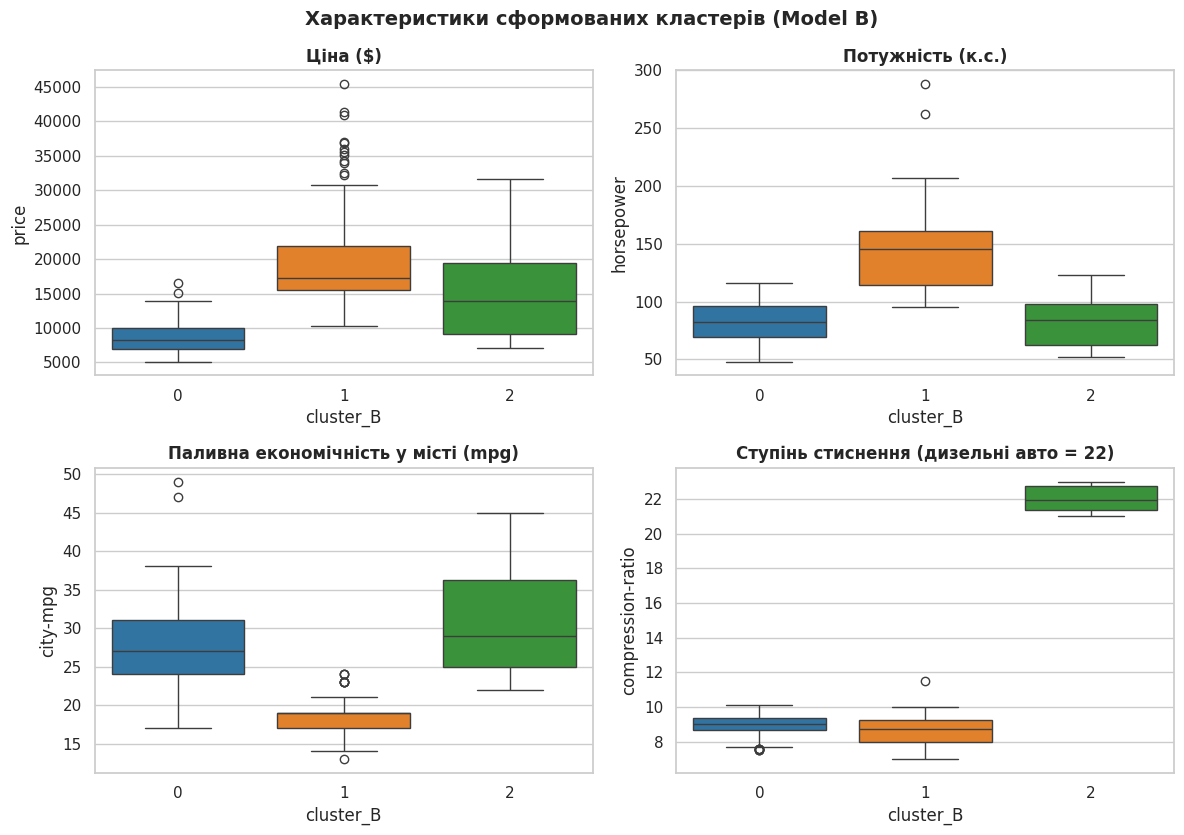

In [7]:
cluster_names = {
    0: "Бюджетний економічний сегмент (Масові авто)",
    1: "Преміальний та спортивний сегмент (Люкс-авто)",
    2: "Дизельний сегмент високої паливної ефективності"
}

for cl in range(3):
    sub = df[df['cluster_B'] == cl]
    print(f"=== {cluster_names[cl]} (Кластер {cl}, n={len(sub)}) ===")
    print(f"Ціна: середня ${sub['price'].mean():.0f}, медіана ${sub['price'].median():.0f}")
    print(f"Потужність: {sub['horsepower'].mean():.1f} к.с.")
    print(f"Маса: {sub['curb-weight'].mean():.0f} кг, Колісна база: {sub['wheel-base'].mean():.1f}\"")
    print(f"Витрата в місті: {sub['city-mpg'].mean():.1f} mpg")
    print(f"Ступінь стиснення: {sub['compression-ratio'].mean():.1f}")
    print(f"Паливо: {sub['fuel-type'].value_counts().to_dict()}")
    print(f"Привод: {sub['drive-wheels'].value_counts().to_dict()}")
    print(f"Топ марки: {sub['make'].value_counts().head(3).to_dict()}\n")

fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))
sns.boxplot(x='cluster_B', y='price', data=df, ax=axes[0, 0], palette=colors)
axes[0, 0].set_title('Ціна ($)', fontweight='bold')
sns.boxplot(x='cluster_B', y='horsepower', data=df, ax=axes[0, 1], palette=colors)
axes[0, 1].set_title('Потужність (к.с.)', fontweight='bold')
sns.boxplot(x='cluster_B', y='city-mpg', data=df, ax=axes[1, 0], palette=colors)
axes[1, 0].set_title('Паливна економічність у місті (mpg)', fontweight='bold')
sns.boxplot(x='cluster_B', y='compression-ratio', data=df, ax=axes[1, 1], palette=colors)
axes[1, 1].set_title('Ступінь стиснення (дизельні авто = 22)', fontweight='bold')
plt.suptitle('Характеристики сформованих кластерів (Model B)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## Завдання 9. Порівняльний аналіз (Відповіді на запитання)
1. **Як відбір ознак вплинув на якість кластеризації?** Усунення мультиколінеарності та шуму розріджених категорій подвоїло силуетний показник: Silhouette зріс із 0.1971 до 0.3934, а індекс Девіса-Болдіна покращився з 1.8109 до 1.0182.
2. **Чи змінилася оптимальна кількість кластерів після відбору ознак?** Ні, «точка ліктя» на кривій Inertia стабільно зафіксована при $k=3$ для всіх представлень даних.
3. **Чи покращило PCA розділення об'єктів на кластери?** PCA ортогоналізувало ознаки та знизило розмірність, але його силует (0.2238) нижчий за відібрані ознаки (0.3934), оскільки лінійні комбінації змішують специфічні бінарні контрасти.
4. **Скільки головних компонент необхідно для збереження 90–95 % дисперсії?** Для $\ge 90\%$ потрібно 7 компонент (92.53%), а для $\ge 95\%$ — 9 компонент (96.53%).
5. **Чи можна суттєво зменшити кількість ознак без погіршення якості кластеризації?** Так, скорочення простору з 65 до 12 ознак (на 81.5%) не лише зберегло інформативність, а й суттєво покращило чіткість кластерів.
6. **Для якого представлення отримано найвище значення Silhouette Score?** Для Набору B (відібрані ознаки) — 0.3934.
7. **Чи узгоджуються результати різних метрик кластеризації?** Так, Набір B одночасно є лідером за Silhouette (0.3934), Davies-Bouldin (1.0182 — мінімум) та Calinski-Harabasz (106.4 — максимум).
8. **Наскільки легко інтерпретувати кластери, отримані на початкових ознаках та після PCA?** Кластери на відібраних вихідних ознаках інтерпретуються інтуїтивно та мають фізичний зміст (ціна, потужність, дизель), тоді як інтерпретація головних компонент PCA є абстрактною.


## Завдання 10. Побудова фінального pipeline
Схема оптимального конвеєра:
$$\text{Raw Data} \rightarrow \text{Imputation (median/mode)} \rightarrow \text{Drop symboling} \rightarrow \text{Feature Selection (12 ознак)} \rightarrow \text{ColumnTransformer (Scaler + OHE)} \rightarrow \text{K-Means (k=3)} \rightarrow \text{Profiling}$$


In [8]:
from sklearn.pipeline import Pipeline

# Кінцевий трансформер даних
final_preprocessor = ColumnTransformer([
    ('num', StandardScaler(), selected_num),
    ('cat', OneHotEncoder(drop='first', sparse_output=False), selected_cat)
])

# Фінальний Pipeline кластеризації
clustering_pipeline = Pipeline([
    ('preprocessor', final_preprocessor),
    ('kmeans', KMeans(n_clusters=3, random_state=42, n_init=10))
])

# Навчання на очищених даних
clustering_pipeline.fit(X_raw)
final_labels = clustering_pipeline.named_steps['kmeans'].labels_

print("Фінальний Pipeline успішно навчено.")
print("Розподіл об'єктів за кластерами:", pd.Series(final_labels).value_counts().to_dict())
print("Фінальний Silhouette Score:", round(silhouette_score(final_preprocessor.transform(X_raw), final_labels), 4))


Фінальний Pipeline успішно навчено.
Розподіл об'єктів за кластерами: {0: 119, 1: 66, 2: 20}
Фінальний Silhouette Score: 0.3934


## Висновки
1. Досліджено інженерію даних для задачі кластеризації на основі 205 автомобілів датасету Automobile Data.
2. Сформовано 3 простори ознак: повний (65), відібрані ознаки (12) та PCA (7 компонент, що покривають 92.53% дисперсії).
3. Визначено оптимальну кількість кластерів $k = 3$ на основі Elbow Method та Silhouette Score.
4. Відбір ознак (Model B) продемонстрував найкращу якість за всіма метриками (Silhouette = 0.3934, Davies-Bouldin = 1.0182, Calinski-Harabasz = 106.4).
5. Сформовано 3 змістовні профілі: доступні економічні авто (119 од.), люксові та спортивні авто (66 од.) та спеціалізований дизельний клас високої паливної ефективності (20 од.).


## AI Black Box
У цій лабораторній роботі я використовував Google Gemini як допоміжного консультанта виключно для уточнення синтаксису розрахунку силуету для різних розмірностей ColumnTransformer та оптимізації легенди центроїдів у matplotlib. Наприклад, я попросив ШІ: «Як коректно розрахувати та нанести емпіричні центроїди багатовимірних кластерів K-Means на двовимірну площину PC1 x PC2 у scikit-learn?». Отриману пораду щодо обчислення покластерних середніх значень проєкцій використано для побудови Рис. 4. Я перевірив результат шляхом запуску коду в середовищі, звірки розмірностей матриць та порівняння значень інерції. Самостійно було розроблено стратегію обробки пропусків, кореляційного відбору ознак, визначення порогів дисперсії PCA, підбору k=3 та інженерного профілювання кластерів. ШІ спочатку запропонував трансформувати центри кластерів Набору B через метод pca.transform(km.cluster_centers_), що спричинило б помилку розмірності через різну кількість стовпців, тому я виправив це прямою проєкцією вибірки та обчисленням локальних центрів. Цікавим кейсом стало те, що додавання ступеня стиснення до 6 числових ознак дозволило алгоритму самостійно та ідеально відокремити всі 20 дизельних авто датасету.
